# Interior Point 1: Linear Programs

**Seong Cho** · ACME Volume 2, Lab 16

**Lab objective:** implement a primal-dual Interior Point method for linear programs, an alternative to the Simplex algorithm with much better theoretical convergence properties, and use it to fit a least absolute deviations line.

<sub>Lab specification from the *Volume 2* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

The solution code uses `np.row_stack()`, which NumPy 2.0 deprecated as an alias of `np.vstack()`. The code is kept as written, and the setup cell hides that one `DeprecationWarning`.

In [1]:
import warnings
import numpy as np
from scipy import linalg as la
from scipy.stats import linregress
from scipy.optimize import linprog
from matplotlib import pyplot as plt

warnings.filterwarnings("ignore", message="`row_stack` alias is deprecated", category=DeprecationWarning)

## Introduction

For decades after its invention, the Simplex algorithm was the only competitive method for linear programming. The past 30 years, however, have seen the discovery and widespread adoption of a new family of algorithms that rival (and in some cases outperform) the Simplex algorithm, collectively called *Interior Point methods*. The number of steps the Simplex algorithm needs can grow exponentially with the size of the linear system, so for certain large linear programs it is simply not viable.

The linear constraints define the *feasible region*, whose boundary is a *polytope*, and the optimal point can be found among its vertices. The Simplex Method tests a sequence of vertices; it is certain to finish in a finite number of steps (if the program is neither unbounded nor infeasible), but it does not guarantee an efficient path along the polytope. Interior Point methods instead generate a sequence of points that cut through the interior (or exterior) of the feasible region and converge iteratively to the optimal point. Each step is more expensive to compute, but makes significant progress toward the minimizer, so far fewer iterations are needed. (The spec's Figure 16.1 shows such a path, from a starting point through a 2-D feasible region to the optimal vertex.)

## Primal-Dual Interior Point Methods

Some of the most popular and successful Interior Point methods are *Primal-Dual Interior Point methods*. Consider the linear program

$$\begin{aligned} \text{minimize} \quad & \mathbf{c}^T\mathbf{x} \\ \text{subject to} \quad & A\mathbf{x} = \mathbf{b} \\ & \mathbf{x} \succeq \mathbf{0}, \end{aligned}$$

where $\mathbf{x}, \mathbf{c} \in \mathbb{R}^n$, $\mathbf{b} \in \mathbb{R}^m$, and $A \in \mathbb{R}^{m \times n}$ has full row rank. This is the *primal problem*; its *dual* is

$$\begin{aligned} \text{maximize} \quad & \mathbf{b}^T\boldsymbol{\lambda} \\ \text{subject to} \quad & A^T\boldsymbol{\lambda} + \boldsymbol{\mu} = \mathbf{c} \\ & \boldsymbol{\mu}, \boldsymbol{\lambda} \succeq \mathbf{0}, \end{aligned}$$

where $\boldsymbol{\lambda} \in \mathbb{R}^m$ and $\boldsymbol{\mu} \in \mathbb{R}^n$.

### KKT Conditions

The Karush-Kuhn-Tucker (KKT) conditions give necessary and sufficient conditions for the solutions of the primal and dual problems. The Lagrangian for the primal problem is

$$\mathcal{L}(\mathbf{x}, \boldsymbol{\lambda}, \boldsymbol{\mu}) = \mathbf{c}^T\mathbf{x} + \boldsymbol{\lambda}^T(\mathbf{b} - A\mathbf{x}) - \boldsymbol{\mu}^T\mathbf{x},$$

and the KKT conditions are

$$\begin{aligned} A^T\boldsymbol{\lambda} + \boldsymbol{\mu} &= \mathbf{c} \\ A\mathbf{x} &= \mathbf{b} \\ x_i\mu_i &= 0, \quad i = 1, 2, \ldots, n, \\ \mathbf{x}, \boldsymbol{\mu} &\succeq \mathbf{0}. \end{aligned}$$

Compactly, define the almost-linear function $F$ and set it equal to zero:

$$F(\mathbf{x}, \boldsymbol{\lambda}, \boldsymbol{\mu}) := \begin{bmatrix} A^T\boldsymbol{\lambda} + \boldsymbol{\mu} - \mathbf{c} \\ A\mathbf{x} - \mathbf{b} \\ M\mathbf{x} \end{bmatrix} = \mathbf{0}, \qquad (\mathbf{x}, \boldsymbol{\mu} \succeq \mathbf{0}),$$

where $M = \operatorname{diag}(\mu_1, \mu_2, \ldots, \mu_n)$. The first row of $F$ is dual feasibility, the second primal feasibility, and the last complementary slackness.

## Problem 1: The KKT function $F$

> **Problem 1.** Define a function `interiorPoint()` that will be used to solve the complete interior point problem. This function should accept $A$, $\mathbf{b}$, and $\mathbf{c}$ as parameters, along with the keyword arguments `niter=20` and `tol=1e-16`. The keyword arguments will be used in a later problem.
>
> For this problem, within the `interiorPoint()` function, write a function for the vector-valued function $F$ described above. This function should accept $\mathbf{x}$, $\boldsymbol{\lambda}$, and $\boldsymbol{\mu}$ as parameters and return a 1-dimensional NumPy array with $2n + m$ entries.

Problems 1 to 4 build one function, `interiorPoint()`, shown complete under Problem 4. This part is its nested `KKT_F()`.

## Search Direction

A Primal-Dual Interior Point method is a line search method that starts with an initial guess $(\mathbf{x}_0^T, \boldsymbol{\lambda}_0^T, \boldsymbol{\mu}_0^T)$ and produces a sequence of points converging to $(\mathbf{x}^{*T}, \boldsymbol{\lambda}^{*T}, \boldsymbol{\mu}^{*T})$, the solution to the KKT equations and hence to the linear program. In the spirit of Newton's Method, linearize $F$ about the current point and find the direction that sets the linear approximation to zero:

$$DF(\mathbf{x}, \boldsymbol{\lambda}, \boldsymbol{\mu}) \begin{bmatrix} \Delta\mathbf{x} \\ \Delta\boldsymbol{\lambda} \\ \Delta\boldsymbol{\mu} \end{bmatrix} = -F(\mathbf{x}, \boldsymbol{\lambda}, \boldsymbol{\mu}), \tag{16.1}$$

where the total derivative matrix of $F$ is, block-wise,

$$DF(\mathbf{x}, \boldsymbol{\lambda}, \boldsymbol{\mu}) = \begin{bmatrix} 0 & A^T & I \\ A & 0 & 0 \\ M & 0 & X \end{bmatrix}, \qquad X = \operatorname{diag}(x_1, x_2, \ldots, x_n).$$

Unfortunately, (16.1) often gives a search direction that is too greedy: even small steps may leave the feasible region. To remedy this, define the *duality measure* $\nu$ (the Greek letter for n, pronounced nu)

$$\nu = \frac{\mathbf{x}^T\boldsymbol{\mu}}{n},$$

and use Newton's method to find a direction that strictly decreases $\nu$. That is, solve instead

$$DF(\mathbf{x}, \boldsymbol{\lambda}, \boldsymbol{\mu}) \begin{bmatrix} \Delta\mathbf{x} \\ \Delta\boldsymbol{\lambda} \\ \Delta\boldsymbol{\mu} \end{bmatrix} = -F(\mathbf{x}, \boldsymbol{\lambda}, \boldsymbol{\mu}) + \begin{bmatrix} \mathbf{0} \\ \mathbf{0} \\ \sigma\nu\mathbf{e} \end{bmatrix}, \tag{16.2}$$

where $\mathbf{e} = (1, 1, \ldots, 1)^T$ and $\sigma \in [0, 1)$ is the *centering parameter*. The closer $\sigma$ is to 0, the more the direction resembles the plain Newton direction; the closer to 1, the more it points into the interior of the feasible region.

## Problem 2: The search direction

> **Problem 2.** Within `interiorPoint()`, write a subroutine to compute the search direction $(\Delta\mathbf{x}^T, \Delta\boldsymbol{\lambda}^T, \Delta\boldsymbol{\mu}^T)$ by solving Equation 16.2. Use $\sigma = \frac{1}{10}$ for the centering parameter.
>
> Note that only the last block row of $DF$ will need to be changed at each iteration (since $M$ and $X$ depend on $\boldsymbol{\mu}$ and $\mathbf{x}$, respectively). Use the functions `lu_factor()` and `lu_solve()` from the `scipy.linalg` module to solving the system of equations efficiently.

This is the nested `searchDirection()`; the first two block rows of $DF$ are built once, before the iteration.

## Step Length

Step nearly as far as possible without violating the constraints, staying in the interior of the feasible region. The maximum allowable step lengths for $\mathbf{x}$ and $\boldsymbol{\mu}$ are

$$\alpha_{\max} = \min\{-\mu_i/\Delta\mu_i \mid \Delta\mu_i < 0\}, \qquad \delta_{\max} = \min\{-x_i/\Delta x_i \mid \Delta x_i < 0\}.$$

If all values of $\Delta\boldsymbol{\mu}$ are nonnegative, let $\alpha_{\max} = 1$; likewise $\delta_{\max} = 1$ if all values of $\Delta\mathbf{x}$ are nonnegative. Then back off slightly:

$$\alpha = \min(1, 0.95\alpha_{\max}), \qquad \delta = \min(1, 0.95\delta_{\max}).$$

The next point is

$$\mathbf{x}_{k+1} = \mathbf{x}_k + \delta\Delta\mathbf{x}_k, \qquad (\boldsymbol{\lambda}_{k+1}, \boldsymbol{\mu}_{k+1}) = (\boldsymbol{\lambda}_k, \boldsymbol{\mu}_k) + \alpha(\Delta\boldsymbol{\lambda}_k, \Delta\boldsymbol{\mu}_k).$$

## Problem 3: The step size

> **Problem 3.** Within `interiorPoint()`, write a subroutine to compute the step size after the search direction has been computed. Avoid using loops when computing $\alpha_{\max}$ and $\beta_{\max}$ (use masking and NumPy functions instead).

This is the nested `stepSize()`, which computes the masked minima without loops. It returns $0.95\min(1, \alpha_{\max})$ rather than the spec's $\min(1, 0.95\alpha_{\max})$ (and likewise for $\delta$); the two differ only when the maximum step is longer than 1, where it always takes 0.95 (the spec's rule would step up to 1). One fix was needed: if no entry of $\Delta\boldsymbol{\mu}$ (or $\Delta\mathbf{x}$) is negative, the masked array is empty and `np.min()` raised a `ValueError`; `initial=1` now gives the spec's $\alpha_{\max} = 1$ (or $\delta_{\max} = 1$) in that case.

## Initial Point

The choice of initial point $(\mathbf{x}_0, \boldsymbol{\lambda}_0, \boldsymbol{\mu}_0)$ is important and nontrivial: a naïvely or randomly chosen initial point may cause the algorithm to fail to converge. The spec provides a function that computes an appropriate one (my file names it `startingPoint()`; the spec's printed version calls it `starting_point()`):

In [2]:
# Auxiliary Functions ---------------------------------------------------------
def startingPoint(A, b, c):
    """Calculate an initial guess to the solution of the linear program
    min c^T x, Ax = b, x>=0.
    Reference: Nocedal and Wright, p. 410.
    """
    # Calculate x, lam, mu of minimal norm satisfying both
    # the primal and dual constraints.
    B = la.inv(A @ A.T)
    x = A.T @ B @ b
    lam = B @ A @ c
    mu = c - (A.T @ lam)

    # Perturb x and s so they are nonnegative.
    dx = max((-3./2)*x.min(), 0)
    dmu = max((-3./2)*mu.min(), 0)
    x += dx*np.ones_like(x)
    mu += dmu*np.ones_like(mu)

    # Perturb x and mu so they are not too small and not too dissimilar.
    dx = .5*(x*mu).sum()/mu.sum()
    dmu = .5*(x*mu).sum()/x.sum()
    x += dx*np.ones_like(x)
    mu += dmu*np.ones_like(mu)

    return x, lam, mu

My file also kept two random linear program generators from the lab's starter code: a "square" one, `randomLP(m)`, and a more general `randomLP2(m, n)`. The spec's `randomLP(m, n)` under Problem 4 is defined later in the file and replaces the square version (the second definition shadows the first), so from Problem 4 on, `randomLP` means the spec's two-argument generator.

In [3]:
# Use this linear program generator to test your interior point method.
def randomLP(m):
    """Generate a 'square' linear program min c^T x s.t. Ax = b, x>=0.
    First generate m feasible constraints, then add slack variables.
    Parameters:
        m -- positive integer: the number of desired constraints
             and the dimension of space in which to optimize.
    Returns:
        A -- array of shape (m,n).
        b -- array of shape (m,).
        c -- array of shape (n,).
        x -- the solution to the LP.
    """
    n = m
    A = np.random.random((m,n))*20 - 10
    A[A[:,-1]<0] *= -1
    x = np.random.random(n)*10
    b = A.dot(x)
    c = A.sum(axis=0)/float(n)
    return A, b, -c, x

# This random linear program generator is more general than the first.
def randomLP2(m,n):
    """Generate a linear program min c^T x s.t. Ax = b, x>=0.
    First generate m feasible constraints, then add
    slack variables to convert it into the above form.
    Parameters:
        m -- positive integer >= n, number of desired constraints
        n -- dimension of space in which to optimize
    Returns:
        A -- array of shape (m,n+m)
        b -- array of shape (m,)
        c -- array of shape (n+m,), with m trailing 0s
        v -- the solution to the LP
    """
    A = np.random.random((m,n))*20 - 10
    A[A[:,-1]<0] *= -1
    v = np.random.random(n)*10
    k = n
    b = np.zeros(m)
    b[:k] = A[:k,:].dot(v)
    b[k:] = A[k:,:].dot(v) + np.random.random(m-k)*10
    c = np.zeros(n+m)
    c[:n] = A[:k,:].sum(axis=0)/k
    A = np.hstack((A, np.eye(m)))
    return A, b, -c, v

## Problem 4: The complete interior point method

> **Problem 4.** Complete the implementation of `interiorPoint()`.
>
> Use the function `starting_point()` provided above to select an initial point, then run the iteration `niter` times, or until the duality measure is less than `tol`. Return the optimal point $\mathbf{x}^*$ and the optimal value $\mathbf{c}^T\mathbf{x}^*$.

The duality measure $\nu$ tells us in some sense how close the current point is to the minimizer: the closer $\nu$ is to 0, the closer we are to the optimal point, so printing $\nu$ at each iteration tracks progress and shows convergence. My complete solution to Problems 1 to 4:

In [4]:
# Problems --------------------------------------------------------------------
def interiorPoint(A, b, c, niter=20, tol=1e-16, verbose=False):
    """Solve the linear program min c^T x, Ax = b, x>=0
    using an Interior Point method.

    Parameters:
        A ((m,n) ndarray): Equality constraint matrix with full row rank.
        b ((m, ) ndarray): Equality constraint vector.
        c ((n, ) ndarray): Linear objective function coefficients.
        niter (int > 0): The maximum number of iterations to execute.
        tol (float > 0): The convergence tolerance.

    Returns:
        x ((n, ) ndarray): The optimal point.
        val (float): The minimum value of the objective function.
    """
    # Define m,n
    m = len(b)
    n = len(c)
    # Define the function that returns matrix F
    def KKT_F(x, l, mu):
        F_r1 = A.T@l + mu - c
        F_r2 = A@x - b
        F_r3 = mu*x
        return np.concatenate([F_r1,F_r2,F_r3])
    # Save the first and second block rows of DF since they don't change
    DF_r1 = np.column_stack([np.zeros((n,n)), A.T, np.eye(n)])
    DF_r2 = np.column_stack([A, np.zeros((m,m)), np.zeros((m,n))])
    # Define the function that returns the search direction
    def searchDirection(x, l, mu, s=0.1):
        F = KKT_F(x, l, mu)
        DF_r3 = np.column_stack([np.diag(mu), np.zeros((n,m)), np.diag(x)])
        DF = np.row_stack([DF_r1, DF_r2, DF_r3])
        nu = np.dot(x,mu)/n
        p = np.concatenate([np.zeros(m+n), s*nu*np.ones(n)])
        return la.lu_solve(la.lu_factor(DF), -F + p)
    # Defind the function that returns the stepsize, along with the delta vector
    def stepSize(x, l, mu):
        direction = searchDirection(x, l, mu)
        d_x = direction[:n]
        d_l = direction[n:n+m]
        d_mu = direction[n+m:]
        # Fixed: initial=1 makes the max step 1 when no entry of d_mu (or d_x) is
        # negative, as the spec says; np.min of the empty array raised a ValueError.
        alpha = np.min([1, np.min((-mu/d_mu)[d_mu<0], initial=1)])
        delta = np.min([1, np.min((-x/d_x)[d_x<0], initial=1)])
        return 0.95*alpha, 0.95*delta, d_x, d_l, d_mu
    # Use the predefined function startingPoint to get the initial point
    x, l, mu = startingPoint(A, b, c)
    # Repeat the following for niter times
    for i in range(niter):
        alpha, delta, d_x, d_l, d_mu = stepSize(x, l, mu)
        # Update each of the variables
        x += delta*d_x
        l += alpha*d_l
        mu += alpha*d_mu
        nu = np.dot(x,mu) / n
        # Stopping criteria
        if abs(nu) < tol:
            return x, np.dot(c,x)
    return x, np.dot(c,x)

To test the implementation, the spec provides this generator of a random linear program along with its optimal solution:

In [5]:
def randomLP(m, n):
    A = np.random.random((m,n))*20 - 10
    A[A[:,-1]<0] *= -1
    x = np.random.random(n)*10
    b = np.zeros(m)
    b[:n] = A[:n,:] @ x
    b[n:] = A[n:,:] @ x + np.random.random(m-n)*10
    c = np.zeros(n+m)
    c[:n] = A[:n,:].sum(axis=0)/n
    A = np.hstack((A, np.eye(m)))
    return A, b, -c, x

In the spec's docstring for it: `A` is the $m \times (n+m)$ constraint matrix ($m \ge n$ constraints in $n$ dimensions, plus $m$ slack variables), `b` the constraint vector, `c` the objective with $m$ trailing 0s, and `x` the first $n$ terms of the solution to the LP. The spec's test:

```python
>>> m, n = 7, 5
>>> A, b, c, x = randomLP(m, n)
>>> point, value = interiorPoint(A, b, c)
>>> np.allclose(x, point[:n])
True
```

In [6]:
np.random.seed(16)
m, n = 7, 5
A, b, c, x = randomLP(m, n)
point, value = interiorPoint(A, b, c)
np.allclose(x, point[:n])

True

A larger check: 300 random LPs of assorted sizes, from both two-argument generators. The point must match the generator's solution, and the optimal value must match `scipy.optimize.linprog()` on the same problem (its variables are nonnegative by default).

In [7]:
np.random.seed(160)
for trial in range(300):
    m = np.random.randint(3, 40)
    n = np.random.randint(2, m+1)
    A, b, c, x = (randomLP if trial % 2 else randomLP2)(m, n)
    point, value = interiorPoint(A, b, c)
    ref = linprog(c, A_eq=A, b_eq=b)
    assert np.allclose(point[:n], x) and np.isclose(value, ref.fun)
print("All 300 random LPs agree with the known solution and linprog.")

All 300 random LPs agree with the known solution and linprog.


The square generator from the starter code gives a nonsingular $A$, so $\mathbf{x}$ is the only feasible point; the method finds it too:

In [8]:
np.random.seed(1600)
m = 8
A = np.random.random((m,m))*20 - 10            # The body of the square randomLP(m) above.
A[A[:,-1]<0] *= -1
x = np.random.random(m)*10
b = A.dot(x)
c = -A.sum(axis=0)/float(m)
point, value = interiorPoint(A, b, c)
print(np.allclose(point, x), np.isclose(value, c @ x))

True True


## Least Absolute Deviations (LAD)

Back to fitting a line (or hyperplane) to data. *Least squares* minimizes the sum of the squares of the errors between the data and the line; its solution can be obtained analytically for a linear function, or by optimization methods (such as Conjugate Gradient) for a nonlinear one.

The method of *least absolute deviations* (LAD) measures the error differently. For data points $(y_1, \mathbf{x}_1), \ldots, (y_m, \mathbf{x}_m)$ with $y_i \in \mathbb{R}$ (the *response variables*) and $\mathbf{x}_i \in \mathbb{R}^n$ (the *explanatory variables*), assume the linear model

$$y_i = \boldsymbol{\beta}^T\mathbf{x}_i + b, \quad i = 1, 2, \ldots, m,$$

where $\boldsymbol{\beta} \in \mathbb{R}^n$ and $b \in \mathbb{R}$. The error between the data and the model is

$$\sum_{i=1}^n |\boldsymbol{\beta}^T\mathbf{x}_i + b - y_i|,$$

and we choose $\boldsymbol{\beta}$, $b$ to minimize it.

### Advantages of LAD

LAD is *robust* to outliers: one (or a few) errant data points won't severely affect the fitted line. Indeed, in most cases the best fit line is guaranteed to pass through at least two of the data points. This is desirable when the outliers may be ignored (perhaps because they are due to measurement error or corrupted data). Least squares is much more sensitive to outliers, and so is the better choice when outliers cannot be dismissed (the spec's Figure 16.2 shows the two fits on data with an outlier).

On the other hand, small horizontal perturbations of the data can lead to very different LAD lines, so LAD is less stable than least squares, and sometimes infinitely many lines minimize the LAD error (though one can expect a unique solution in most cases). LAD arises naturally when the residuals $\boldsymbol{\beta}^T\mathbf{x}_i + b - y_i$ follow a Laplace distribution. Ultimately the choice depends on the nature of the data at hand, as well as your own good judgment.

### LAD as a Linear Program

Introduce artificial variables $u_i \ge |\boldsymbol{\beta}^T\mathbf{x}_i + b - y_i|$, split into the two linear constraints $u_i \ge \boldsymbol{\beta}^T\mathbf{x}_i + b - y_i$ and $u_i \ge y_i - \boldsymbol{\beta}^T\mathbf{x}_i - b$ (so the $u_i$ are implicitly nonnegative):

$$\begin{aligned} \text{minimize} \quad & \sum_{i=1}^m u_i \\ \text{subject to} \quad & u_i \ge \boldsymbol{\beta}^T\mathbf{x}_i + b - y_i, \\ & u_i \ge y_i - \boldsymbol{\beta}^T\mathbf{x}_i - b. \end{aligned}$$

A nonnegative slack variable for each inequality turns it into an equality:

$$u_i - \boldsymbol{\beta}^T\mathbf{x}_i - b - s_{2i-1} = -y_i, \qquad u_i + \boldsymbol{\beta}^T\mathbf{x}_i + b - s_{2i} = y_i, \qquad s_{2i-1}, s_{2i} \ge 0.$$

The interior point method assumes all variables are nonnegative, but $\boldsymbol{\beta}$ and $b$ are not, so write them as differences of nonnegative variables, $\boldsymbol{\beta} = \boldsymbol{\beta}_1 - \boldsymbol{\beta}_2$ and $b = b_1 - b_2$:

$$\begin{aligned} u_i - \boldsymbol{\beta}_1^T\mathbf{x}_i + \boldsymbol{\beta}_2^T\mathbf{x}_i - b_1 + b_2 - s_{2i-1} &= -y_i, \\ u_i + \boldsymbol{\beta}_1^T\mathbf{x}_i - \boldsymbol{\beta}_2^T\mathbf{x}_i + b_1 - b_2 - s_{2i} &= y_i, \\ \boldsymbol{\beta}_1, \boldsymbol{\beta}_2 \succeq \mathbf{0}; \quad u_i, b_1, b_2, s_{2i-1}, s_{2i} &\ge 0. \end{aligned}$$

With $\mathbf{y} = (-y_1, y_1, -y_2, y_2, \ldots, -y_m, y_m)^T$, $\boldsymbol{\beta}_i = (\beta_{i,1}, \ldots, \beta_{i,n})^T$ for $i = 1, 2$, all the variables aggregated into

$$\mathbf{v} = (u_1, \ldots, u_m, \beta_{1,1}, \ldots, \beta_{1,n}, \beta_{2,1}, \ldots, \beta_{2,n}, b_1, b_2, s_1, \ldots, s_{2m})^T,$$

and $\mathbf{c} = (1, 1, \ldots, 1, 0, \ldots, 0)^T$ (only the first $m$ entries equal to 1), the objective is $\sum_{i=1}^m u_i = \mathbf{c}^T\mathbf{v}$, and the final form is

$$\begin{aligned} \text{minimize} \quad & \mathbf{c}^T\mathbf{v} \\ \text{subject to} \quad & A\mathbf{v} = \mathbf{y}, \\ & \mathbf{v} \succeq \mathbf{0}, \end{aligned}$$

where $A$ contains the coefficients of the constraints.

### LAD Example

Each row of an array `data` holds $y_i, x_{i,1}, \ldots, x_{i,n}$. The linear program has $3m + 2(n+1)$ variables, and the constraint matrix has $2m$ rows. The spec's setup (try writing out the matrix by hand for small $m, n$ to see why it is correct):

```python
>>> m = data.shape[0]
>>> n = data.shape[1] - 1
>>> c = np.zeros(3*m + 2*(n + 1))
>>> c[:m] = 1
>>> y = np.empty(2*m)
>>> y[::2] = -data[:, 0]
>>> y[1::2] = data[:, 0]
>>> x = data[:, 1:]

>>> A = np.ones((2*m, 3*m + 2*(n + 1)))
>>> A[::2, :m] = np.eye(m)
>>> A[1::2, :m] = np.eye(m)
>>> A[::2, m:m+n] = -x
>>> A[1::2, m:m+n] = x
>>> A[::2, m+n:m+2*n] = x
>>> A[1::2, m+n:m+2*n] = -x
>>> A[::2, m+2*n] = -1
>>> A[1::2, m+2*n+1] = -1
>>> A[:, m+2*n+2:] = -np.eye(2*m, 2*m)

>>> sol = interiorPoint(A, y, c, niter=10)[0]
```

`sol` holds $\mathbf{v} = (u_1, \ldots, u_m, \beta_{1,1}, \ldots, \beta_{1,n}, \beta_{2,1}, \ldots, \beta_{2,n}, b_1, b_2, s_1, \ldots, s_{2m+1})^T$, from which

```python
>>> beta = sol[m:m+n] - sol[m+n:m+2*n]
>>> b = sol[m+2*n] - sol[m+2*n+1]
```

## Problem 5: The LAD line

> **Problem 5.** The file `simdata.txt` contains two columns of data. The first gives the values of the response variables ($y_i$), and the second column gives the values of the explanatory variables ($\mathbf{x}_i$). Find the least absolute deviations line for this data set, and plot it together with the data. Plot the least squares solution as well to compare the results.
>
> ```python
> >>> from scipy.stats import linregress
> >>> slope, intercept = linregress(data[:,1], data[:,0])[:2]
> >>> domain = np.linspace(0,10,200)
> >>> plt.plot(domain, domain*slope + intercept)
> ```

In [9]:
def leastAbsoluteDeviations(filename='simdata.txt'):
    """Generate and show the plot requested in the lab."""
    # Load the data
    data = np.loadtxt(filename)
    # Define m,n,c,y,x
    m = data.shape[0]
    n = data.shape[1] - 1
    c = np.zeros(3*m + 2*(n+1))
    c[:m] = 1
    y = np.empty(2*m)
    y[::2] = -data[:,0]
    y[1::2] = data[:,0]
    x = data[:,1:]
    # Define the matrix A
    A = np.ones((2*m, 3*m + 2*(n+1)))
    A[::2, :m] = np.eye(m)
    A[1::2, :m] = np.eye(m)
    A[::2, m:m+n] = -x
    A[1::2, m:m+n] = x
    A[::2, m+n:m+2*n] = x
    A[1::2, m+n:m+2*n] = -x
    A[::2, m+2*n] = -1
    A[1::2, m+2*n+1] = -1
    A[:, m+2*n+2:] = -np.eye(2*m, 2*m)
    # Solve for the system
    sol = interiorPoint(A, y, c, niter=10)[0]
    # Extract the necessary data beta and b
    beta = sol[m:m+n] - sol[m+n:m+2*n]
    b = sol[m+2*n] - sol[m+2*n+1]
    # Necessary data for least square line obtained by the scipy function
    slope, intercept = linregress(data[:,1], data[:,0])[:2]
    domain = np.linspace(0, 10, 200)
    # Plot the results
    plt.plot(domain, domain*beta + b, 'r', label='LAD')
    plt.plot(domain, domain*slope + intercept, 'm', label='least square')
    plt.scatter(data[:,1], data[:,0], label='data points')
    plt.legend()
    plt.show()

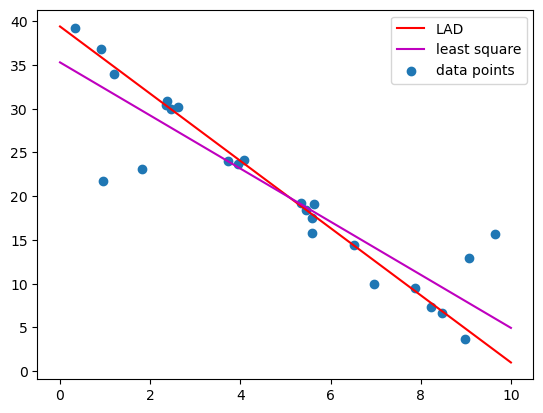

In [10]:
leastAbsoluteDeviations()

The function only plots, so the check rebuilds the same linear program (the spec's construction above) and compares the interior point fit with `linprog()` on a direct LAD formulation in the variables $(u_1, \ldots, u_m, \beta, b)$, with $\beta$ and $b$ free. With the spec's `niter=10` the fit is close but not fully converged; the default 20 iterations matches to many digits.

In [11]:
data = np.loadtxt('simdata.txt')
m, n = data.shape[0], data.shape[1] - 1
c = np.zeros(3*m + 2*(n + 1)); c[:m] = 1
y = np.empty(2*m); y[::2] = -data[:, 0]; y[1::2] = data[:, 0]
x = data[:, 1:]
A = np.ones((2*m, 3*m + 2*(n + 1)))
A[::2, :m] = np.eye(m); A[1::2, :m] = np.eye(m)
A[::2, m:m+n] = -x; A[1::2, m:m+n] = x
A[::2, m+n:m+2*n] = x; A[1::2, m+n:m+2*n] = -x
A[::2, m+2*n] = -1; A[1::2, m+2*n+1] = -1
A[:, m+2*n+2:] = -np.eye(2*m, 2*m)

# Direct LAD: minimize sum(u) s.t. -u <= X beta + b - y <= u.
X1 = np.column_stack([x, np.ones(m)])
ref = linprog(np.r_[np.ones(m), np.zeros(n+1)],
              A_ub=np.block([[-np.eye(m), X1], [-np.eye(m), -X1]]),
              b_ub=np.r_[data[:, 0], -data[:, 0]],
              bounds=[(0, None)]*m + [(None, None)]*(n+1))
print(f"linprog:            beta = {ref.x[m]:.6f}, b = {ref.x[m+1]:.6f}, error = {ref.fun:.6f}")
for niter in (10, 20):
    sol, val = interiorPoint(A, y, c, niter=niter)
    beta, b = sol[m:m+n] - sol[m+n:m+2*n], sol[m+2*n] - sol[m+2*n+1]
    print(f"interiorPoint ({niter}): beta = {beta[0]:.6f}, b = {b:.6f}, error = {val:.6f}")
    assert np.allclose([beta[0], b], ref.x[m:], atol=1e-2 if niter == 10 else 1e-6)

slope, intercept = linregress(data[:, 1], data[:, 0])[:2]
print(f"least squares:      slope = {slope:.6f}, intercept = {intercept:.6f}")

linprog:            beta = -3.839065, b = 39.402249, error = 60.622105
interiorPoint (10): beta = -3.841322, b = 39.405015, error = 60.656664
interiorPoint (20): beta = -3.839065, b = 39.402249, error = 60.622105
least squares:      slope = -3.035603, intercept = 35.301671
